# exploration traindataset 

In [6]:
# libraries
import plotly.express as px
import matplotlib.pyplot as plt
import pandas as pd
# global variables
CORPUS_PATH = "../corpora-collection/sunset-corpus/src/normalized/"

In [4]:
df = pd.read_csv("src/city_country_metadata.tsv", sep="\t")
df.columns

Index(['ID', 'filename', 'title', 'author', 'gnd', 'birthYear', 'deathYear',
       'gender', 'source', 'pubYear', 'label', 'Source_Genre', 'textClass',
       'genre'],
      dtype='str')

In [36]:
df.gender.value_counts()

gender
männlich    142
weiblich     14
Name: count, dtype: int64

In [40]:
df.loc[df.textClass=="Urban"].gender.value_counts()

gender
männlich    53
weiblich     3
Name: count, dtype: int64

In [16]:
for subset in df.textClass.unique():
    sliceDf = df.loc[df.textClass==subset]

    token_count = 0

    for file in sliceDf.filename:
        with open(CORPUS_PATH + file) as f:
            text = f.read()
        token_count = token_count + len(text.split())

    print(subset, "\tn files: ", len(sliceDf), "\tn tokens: ", token_count)
    print("\tn authors", len(sliceDf.author.unique()), "\tn male", len(sliceDf.loc[sliceDf.gender=="männlich"].author.unique()), "\tn female", len(sliceDf.loc[sliceDf.gender=="weiblich"].author.unique()),)
    print("\tfrom: ", sliceDf.pubYear.min(), "\tto: ", sliceDf.pubYear.max())

Urban 	n files:  56 	n tokens:  6181031
	n authors 25 	n male 22 	n female 3
	from:  1819 	to:  1935
Rural 	n files:  61 	n tokens:  4853519
	n authors 38 	n male 32 	n female 6
	from:  1781 	to:  1918
Other 	n files:  39 	n tokens:  2075385
	n authors 21 	n male 20 	n female 1
	from:  1797 	to:  1919


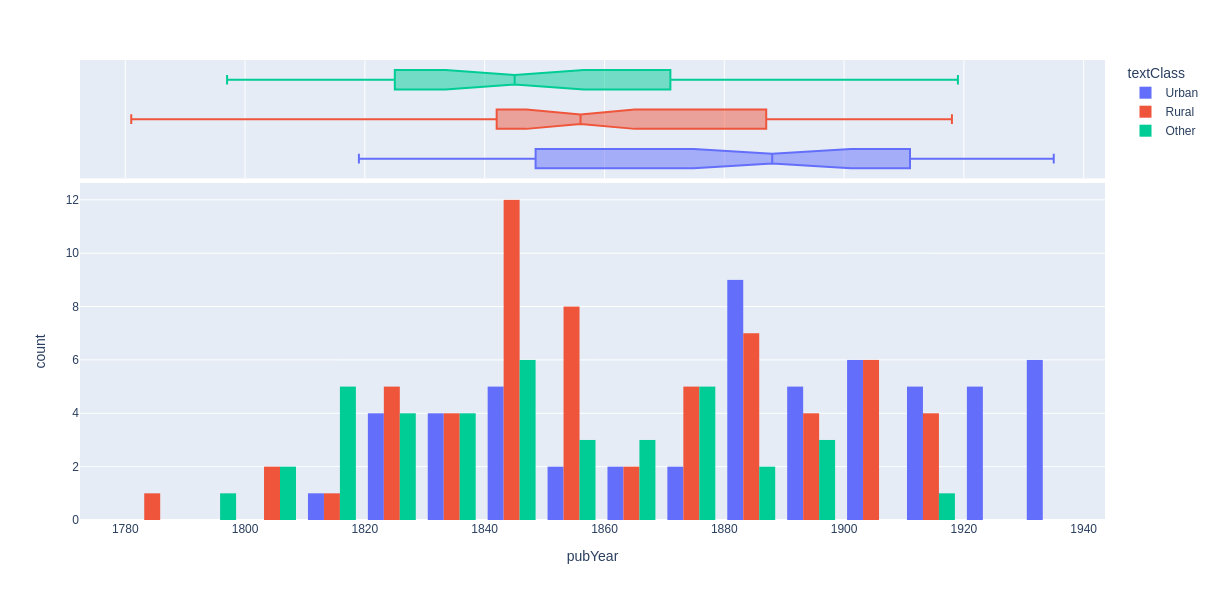

In [35]:
px.histogram(df, x="pubYear", color="textClass", barmode='group', marginal="box",height=600)

In [24]:
meta = pd.read_csv("../../GitHub/corpora-collection/sunset-corpus/metadata_updated-v2.csv")
meta.columns

Index(['filename', 'ID', 'title', 'gndID', 'author', 'birthYear', 'deathYear',
       'gender', 'nationality', 'pubYear', 'numTokens', 'timeslotPubYear',
       'timeslotBirthYear', 'source', 'n_chunks', 'textClass',
       'mean_prob_prose', 'mean_prob_drama', 'mean_prob_lyric',
       'corpusSubset'],
      dtype='str')

In [33]:
meta.gender.value_counts()

gender
männlich    5589
weiblich     794
Name: count, dtype: int64

In [34]:
meta.drop_duplicates(subset="author").gender.value_counts()

gender
männlich    626
weiblich    140
Name: count, dtype: int64

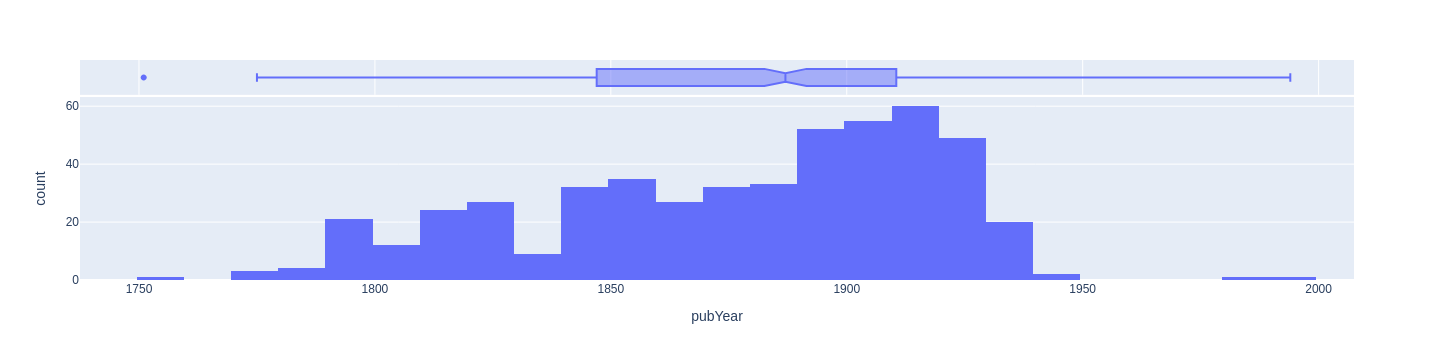

In [26]:
px.histogram(meta.loc[meta.corpusSubset=="core"], x="pubYear", marginal="box")